# Urban Heat Island Predictor — Bengaluru

## 1. Data Acquisition & Setup

In [710]:
# Importing packages
import os, json
import numpy as np
import rasterio, rasterio.mask
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

In [711]:
# File strucutre
# Urban Heat Island/
# ├── data/
# │   └── raw/
# ├── outputs/
# └── Notebooks/
#     └── your_notebook.ipynb

base_dir = os.path.dirname(os.getcwd())

scene_dir = os.path.join(base_dir, "data", "raw")
out_dir = os.path.join(base_dir, "outputs")

# Download and extract Landsat data into raw folder

def path(file):
    return scene_dir + r"\LC08_L2SP_144051_20250414_20250424_02_T1_" + file + r".TIF"

In [712]:
# Extracting LST_MULT and LST_ADD

MTL_JSON_PATH = rf"{scene_dir}\LC08_L2SP_144051_20250414_20250424_02_T1_MTL.json"

with open(MTL_JSON_PATH, 'r') as file:
    data = json.load(file)
    

LST_MULT = float(data["LANDSAT_METADATA_FILE"]["LEVEL2_SURFACE_TEMPERATURE_PARAMETERS"]["TEMPERATURE_MULT_BAND_ST_B10"])
LST_ADD = float(data["LANDSAT_METADATA_FILE"]["LEVEL2_SURFACE_TEMPERATURE_PARAMETERS"]["TEMPERATURE_ADD_BAND_ST_B10"])
EMIS_MULT = 0.0001

In [713]:
bands = []
for name in ["SR_B4", "SR_B5", "SR_B6", "ST_B10", "SR_B3", "ST_EMIS", "SR_B2", "SR_B7"]:
    with rasterio.open(path(name)) as file:
        bands.append(file.read(1))

b2 = np.array(bands[6]).astype("float32") # Blue Band: Stores how much blue is reflected back
b3 = np.array(bands[4]).astype("float32") # Green band: Stores how much green is reflected back
b4 = np.array(bands[0]).astype("float32") # Red Band: Stores how much red is reflected back
b5 = np.array(bands[1]).astype("float32") # NIR Band: Stores how much Near Infra Red is reflected back
b6 = np.array(bands[2]).astype("float32") # SWIR-1: Stores data on reflected rays that are not sensitive to concrete like NIR
b7 = np.array(bands[7]).astype("float32") # SWIR-2: Stores data on reflected rays that are sensitive to moisture in soil and vegetation
b10 = np.array(bands[3]).astype("float32") # Thermal Infrared Band: Stores data on the radiation emitted by the land
EMIS = np.array(bands[5]).astype("float32") # Emmisivity: Measures how efficiently a surface radiates heat

with rasterio.open(path("QA_PIXEL")) as src:
    qa = np.array(src.read(1)).astype("uint16")
    qa_crs = src.crs # Original Co-ordinate reference system
    qa_tr = src.transform # Transform from pixel co-ordinates to real world co-ordinates int the format of CRS

In [714]:
bad = ((qa & 0b00001000) != 0) | ((qa & 0b00010000 != 0)) # For masking bad pixels (marked by USGS)

In [715]:
b2[bad] = np.nan # Setting bad pixels to nan
b3[bad] = np.nan
b4[bad] = np.nan 
b5[bad] = np.nan
b6[bad] = np.nan
b7[bad] = np.nan
b10[bad] = np.nan
b10[b10 == 0] = np.nan
EMIS[EMIS == -9999] = np.nan

In [716]:
b2 = np.clip(b2 * 0.0000275 - 0.2, 0, 1) # Scaling with values published by USGS; clipping to ensure values stay between 0% and 100%
b3 = np.clip(b3 * 0.0000275 - 0.2, 0, 1) 
b4 = np.clip(b4 * 0.0000275 - 0.2, 0, 1) 
b5 = np.clip(b5 * 0.0000275 - 0.2, 0, 1)
b6 = np.clip(b6 * 0.0000275 - 0.2, 0, 1)
b7 = np.clip(b7 * 0.0000275 - 0.2, 0, 1)

In [717]:
with np.errstate(divide="ignore", invalid="ignore"):
    NDVI = (b5 - b4) / (b5 + b4) # Normalized Difference Vegetation Index - Used to indicate greeness
    NDBI = (b6 - b5) / (b6 + b5) # Normalized Difference Built-up Index - Used to indicate construction
    LST  = b10 * LST_MULT + LST_ADD - 273.15 # Land surface Temperature 
    MNDWI = (b3 - b6) / (b3 + b6) # Used to detect water bodies
    EMIS = EMIS * 0.0001 # How efficiently a surface emits heat
    ALBEDO = 0.356 * b2 + 0.130 * b4 + 0.373 * b5 + 0.085 * b6 + 0.072 * b7 - 0.0018 # How much sunlight a surface reflects back
    BSI = ((b6 + b4) - (b5 + b2)) / ((b6 + b4) + (b5 + b2)) # Detects bare dry soil from built-up constructions

In [718]:
city = ox.geocode_to_gdf("Bangalore, Karnataka, India") # Downloading the GDF for Bangalore

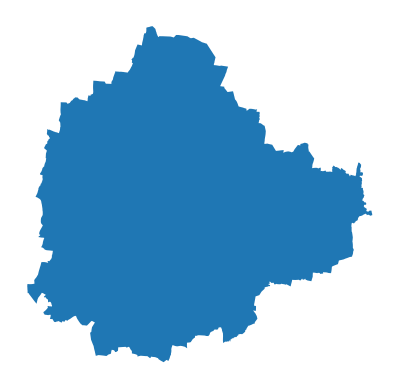

In [719]:
ax = ox.projection.project_gdf(city).plot()
_ = ax.axis('off')

In [720]:
city_proj = city.to_crs(qa_crs) # Converting CRS of Bangalore from format by Osmnx to the format used by Landsat 

In [721]:
geometries = [geom.__geo_interface__ for geom in city_proj.geometry]

## 2. Feature Engineering

In [723]:
def clip_to_city(array, name, profile_base): # Clipping the properties to only store for pixels of Bangalore
    tmp = f"temp_{name}.TIF"
    with rasterio.open(tmp, "w", **profile_base) as f: # Creating a temp file as rasterio mask requires a file for the process
        f.write(array.astype("float32"), 1)
    with rasterio.open(tmp) as f:
        clipped, new_tr = rasterio.mask.mask(f, geometries, crop=True, nodata=np.nan)
    os.remove(tmp)
    return clipped.squeeze(), new_tr

In [724]:
profile_base = { # Paramters needed for rasterio.open to open files
    "driver": "GTiff", 
    "dtype": "float32", 
    "count": 1,
    "crs": qa_crs, 
    "transform": qa_tr,
    "width": NDVI.shape[1], 
    "height": NDVI.shape[0], 
    "nodata": np.nan
}

NDVI_C, new_tr = clip_to_city(NDVI, "NDVI", profile_base) 
NDBI_C, _     = clip_to_city(NDBI, "NDBI", profile_base)
LST_C,  _     = clip_to_city(LST,  "LST",  profile_base)
EMIS_C, _     = clip_to_city(EMIS, "EMIS", profile_base)
MNDWI_C, _    = clip_to_city(MNDWI,"MNDWI",profile_base)
ALBEDO_C, _   = clip_to_city(ALBEDO,"ALBEDO",profile_base)
BSI_C, _      = clip_to_city(BSI,  "BSI",  profile_base)

In [2]:
def property_saving(prop, name, profile):
    with rasterio.open(out_dir + fr"\bangalore_{name}.TIF", "w", **profile) as file:
        file.write(prop.astype("float32"), 1)

In [726]:
profile = {
    "driver": "GTiff",
    "dtype": "float32",
    "count": 1,
    "crs": qa_crs,
    "transform": new_tr,
    "width": NDVI_C.shape[1],
    "height": NDVI_C.shape[0],
    "nodata": np.nan
}

property_saving(NDVI_C, "ndvi", profile) # Saving properties locally for later use
property_saving(NDBI_C, "ndbi", profile)
property_saving(LST_C, "lst", profile)
property_saving(EMIS_C, "emis", profile)
property_saving(MNDWI_C, "mndwi", profile)
property_saving(ALBEDO_C, "albedo", profile)
property_saving(BSI_C, "bsi", profile)

In [ ]:
plt.imshow(LST_C, cmap='RdYlGn') # Visualisaing the properties
plt.colorbar()
plt.title('LST')
plt.show()

In [728]:
clipped_shape = NDVI_C.shape # Storing original shape of properties before performing ravel
NDVI_C = NDVI_C.ravel()
NDBI_C = NDBI_C.ravel()
LST_C = LST_C.ravel()
MNDWI_C = MNDWI_C.ravel()
EMIS_C = EMIS_C.ravel()
ALBEDO_C = ALBEDO_C.ravel()
BSI_C = BSI_C.ravel()

In [772]:
clipped_shape

(1141, 1172)

In [774]:
col, row = np.meshgrid(
    np.arange(0, clipped_shape[1], 1),
    np.arange(0, clipped_shape[0], 1)
)

tile_row = row // 30 # Creating tiles of size 50x50 because pixels close together have similar features.
tile_col = col // 30 # By training using tiles we make sure that model doesn't learn 
                     # local patterns (factors found in specific places that may not be found elsewhere) and has a more general nature

df = pd.DataFrame({ # Making a new table with all the properties
    "NDVI": NDVI_C,
    "NDBI": NDBI_C,
    "LST": LST_C,
    "MNDWI": MNDWI_C,
    "EMIS": EMIS_C,
    "ALBEDO": ALBEDO_C,
    "BSI": BSI_C,
    "row": row.ravel(),
    "col": col.ravel(),
    "tile_row": tile_row.ravel(),
    "tile_col": tile_col.ravel(),
})
df["tile_id"] = df["tile_row"].astype(str) + "_" + df["tile_col"].astype(str)
df = df.dropna()

In [775]:
df.to_csv(out_dir + r"/pixels.csv", index=False) # Saving the table
print(df.head())

          NDVI      NDBI        LST     MNDWI    EMIS    ALBEDO       BSI  \
1591  0.265822  0.092297  40.290955 -0.431905  0.9817  0.186840  0.159431   
1592  0.306996  0.056704  40.414001 -0.433919  0.9821  0.181357  0.131233   
1593  0.373135  0.051112  40.509705 -0.479949  0.9827  0.178543  0.111423   
1594  0.335182  0.072625  40.612244 -0.481930  0.9823  0.179113  0.135756   
1595  0.317484  0.080757  40.451599 -0.478913  0.9844  0.182800  0.143094   

      row  col  tile_row  tile_col tile_id  
1591    1  419         0        13    0_13  
1592    1  420         0        14    0_14  
1593    1  421         0        14    0_14  
1594    1  422         0        14    0_14  
1595    1  423         0        14    0_14  


## 3. Exploratory Data Analysis

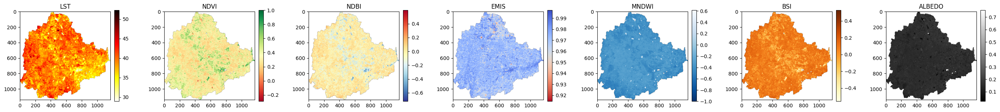

In [777]:
fig, axes = plt.subplots(1, 7, figsize=(28, 5))

with rasterio.open(out_dir+"/bangalore_lst.tif") as src:
    lst_plot = src.read(1)
    c = axes[0].imshow(lst_plot, cmap="hot_r")
    axes[0].set_title("LST")
    fig.colorbar(c, ax=axes[0], fraction=0.046, pad=0.04)
with rasterio.open(out_dir+"/bangalore_ndvi.tif") as src:
    ndvi_plot = src.read(1)
    c = axes[1].imshow(ndvi_plot, cmap="RdYlGn")
    axes[1].set_title("NDVI")
    fig.colorbar(c, ax=axes[1], fraction=0.046, pad=0.04)
with rasterio.open(out_dir+"/bangalore_ndbi.tif") as src:
    ndbi_plot = src.read(1)
    c = axes[2].imshow(ndbi_plot, cmap="RdYlBu_r")
    axes[2].set_title("NDBI")
    fig.colorbar(c, ax=axes[2], fraction=0.046, pad=0.04)
with rasterio.open(out_dir+"/bangalore_emis.tif") as src:
    emis_plot = src.read(1)
    c = axes[3].imshow(emis_plot, cmap="coolwarm_r")
    axes[3].set_title("EMIS")
    fig.colorbar(c, ax=axes[3], fraction=0.046, pad=0.04)
with rasterio.open(out_dir+"/bangalore_mndwi.tif") as src:
    mndwi_plot = src.read(1)
    c = axes[4].imshow(mndwi_plot, cmap="Blues_r")
    axes[4].set_title("MNDWI")
    fig.colorbar(c, ax=axes[4], fraction=0.046, pad=0.04)
with rasterio.open(out_dir+"/bangalore_bsi.tif") as src:
    bsi_plot = src.read(1)
    c = axes[5].imshow(bsi_plot, cmap="YlOrBr")
    axes[5].set_title("BSI")
    fig.colorbar(c, ax=axes[5], fraction=0.046, pad=0.04)
with rasterio.open(out_dir+"/bangalore_albedo.tif") as src:
    albedo_plot = src.read(1)
    c = axes[6].imshow(albedo_plot, cmap="gray")
    axes[6].set_title("ALBEDO")
    fig.colorbar(c, ax=axes[6], fraction=0.046, pad=0.04)

plt.tight_layout(pad=2.0)
plt.savefig(out_dir+"/maps.png")

## 4. Model Training & Evaluation

In [779]:
df = pd.read_csv(out_dir + r"\pixels.csv")

y = df["LST"]
tile_ids = df["tile_id"]

In [780]:
df["norm_row"] = df["row"] / df["row"].max()
df["norm_col"] = df["col"] / df["col"].max()

In [781]:
train_vals, test_vals = train_test_split( # Performing train test split on tile ids as it is better to train on tiles than individual pixels
    df["tile_id"].unique(),
    test_size=0.2,
    random_state=42
)

In [782]:
features = ["NDVI", "NDBI", "EMIS", "MNDWI", "norm_row", "norm_col", "ALBEDO", "BSI"]

X_train = df[df["tile_id"].isin(train_vals)][features]

X_test = df[df["tile_id"].isin(test_vals)][features]

y_train = df[df["tile_id"].isin(train_vals)]["LST"]

y_test = df[df["tile_id"].isin(test_vals)]["LST"]

In [783]:
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error

model = XGBRegressor(
    n_estimators=600,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("R²:", r2_score(y_test, y_pred)) # R2 score closer to 1 is better
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R²: 0.7459370851247145
RMSE: 1.151677257045971


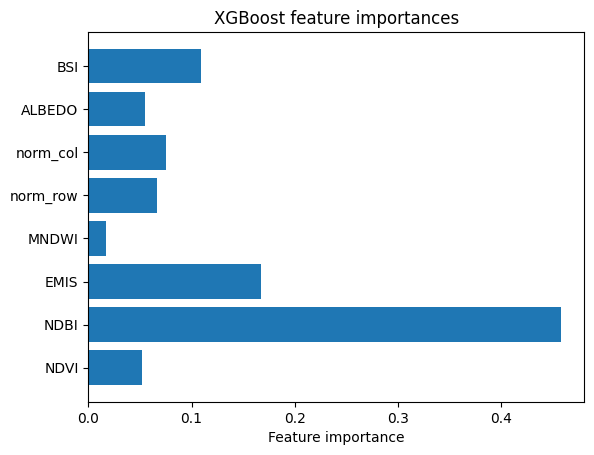

In [784]:
import matplotlib.pyplot as plt

importances = model.feature_importances_ # To see the importance of each model

plt.barh(features, importances)
plt.xlabel("Feature importance")
plt.title("XGBoost feature importances")
plt.show()

## 5. SHAP Feature Importance

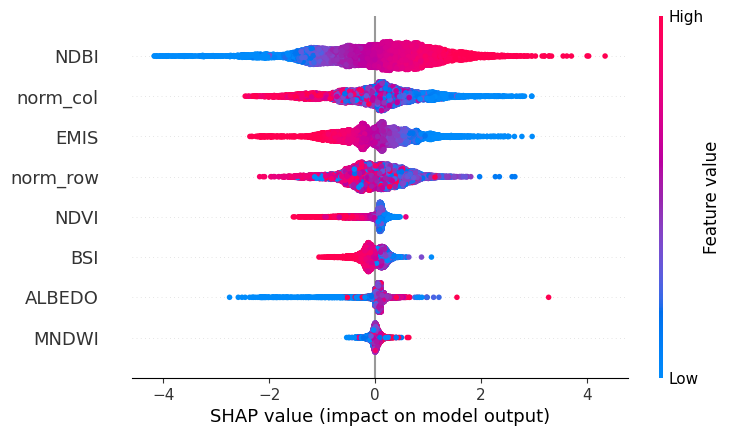

In [786]:
import shap

X_sample = X_train.sample(10000, random_state=42) # Using only a small sample of values as the total 

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_sample)

shap.plots.beeswarm(shap_values) # Creating a beeswarm plot to understand the importance and impact of features

In [787]:
y_pred = model.predict(df[["NDVI", "NDBI", "EMIS", "MNDWI", "norm_row", "norm_col", "ALBEDO", "BSI"]])

pred_raster = np.full(clipped_shape, np.nan) # Converting back to original shape
pred_raster[df["row"].values.astype(int), 
            df["col"].values.astype(int)] = y_pred

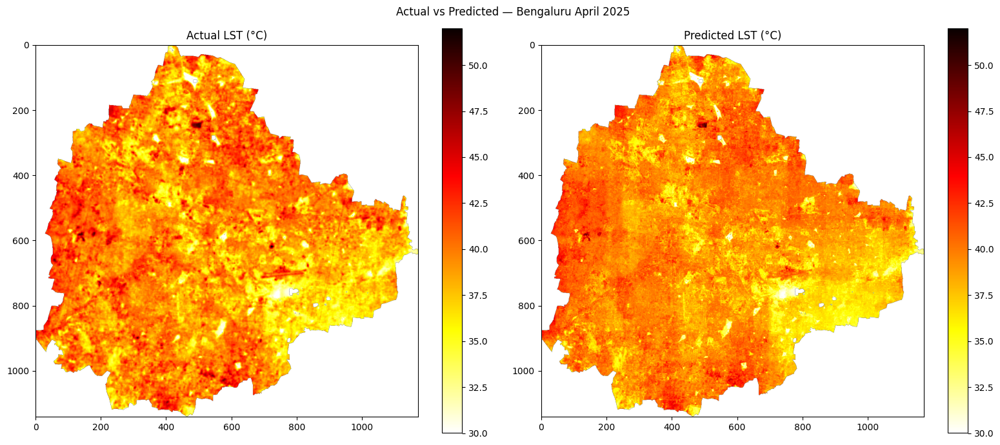

In [788]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7)) # Plotting the results for a side by side comparison

with rasterio.open(out_dir + "/bangalore_lst.tif") as src:
    lst_actual = src.read(1)

im1 = axes[0].imshow(lst_actual, cmap="hot_r", vmin=30, vmax=52)
axes[0].set_title("Actual LST (°C)")
fig.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(pred_raster, cmap="hot_r", vmin=30, vmax=52)
axes[1].set_title("Predicted LST (°C)")
fig.colorbar(im2, ax=axes[1])

plt.suptitle("Actual vs Predicted — Bengaluru April 2025")
plt.tight_layout()
plt.show()

In [789]:
import joblib
joblib.dump(model, out_dir+"/xgb_lst_model.joblib") # Saving the model

['C:\\Users\\nisha\\Urban Heat Island\\outputs/xgb_lst_model.joblib']

## 6. Cooling Intervention Simulation

In [791]:
filtered_df = df[df["LST"] > np.nanpercentile(df["LST"], 90)].copy() # Taking the top 10% hottest spots

In [792]:
tree_planted_df = filtered_df.copy() # Assumed changes after planting trees
tree_planted_df["NDVI"] += 0.3
tree_planted_df["NDBI"] -= 0.1

green_roof_df = filtered_df.copy() # Assumed changes after implementing green roofs
green_roof_df["NDVI"] += 0.15
green_roof_df["NDBI"] -= 0.1
green_roof_df["ALBEDO"] += 0.1

In [793]:
# New predictions
pred_filtered = model.predict(filtered_df[features]) 
pred_trees = model.predict(tree_planted_df[features])
pred_roof = model.predict(green_roof_df[features])

delta_trees = pred_filtered - pred_trees
delta_roof = pred_filtered - pred_roof

delta_trees = np.clip(delta_trees, 0, None) # Removing negative delta values (imply that temperature has increased which is innacurate)
delta_roof = np.clip(delta_roof, 0, None)

In [794]:
# Converting all predictions to original shape
pred_roof_raster = pred_raster.copy()
pred_roof_raster[filtered_df["row"].values.astype(int),
                   filtered_df["col"].values.astype(int)] = pred_roof

pred_trees_raster = pred_raster.copy()
pred_trees_raster[filtered_df["row"].values.astype(int),
                   filtered_df["col"].values.astype(int)] = pred_trees

delta_trees_raster = np.full(clipped_shape, np.nan)
delta_trees_raster[filtered_df["row"].values.astype(int),
                   filtered_df["col"].values.astype(int)] = delta_trees

delta_roof_raster = np.full(clipped_shape, np.nan)
delta_roof_raster[filtered_df["row"].values.astype(int),
                   filtered_df["col"].values.astype(int)] = delta_roof

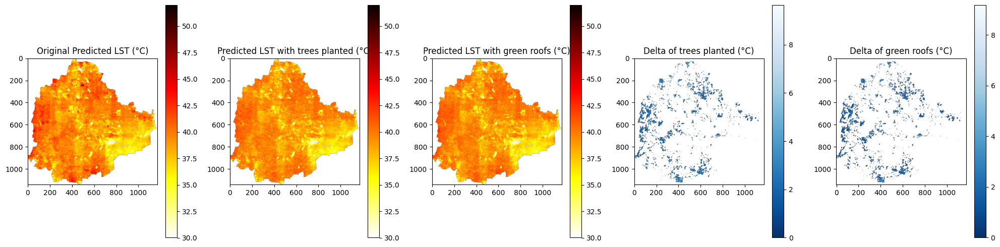

In [795]:
# Side by side comparison of LST after new implementations
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

im1 = axes[0].imshow(pred_raster, cmap="hot_r", vmin=30, vmax=52)
axes[0].set_title("Original Predicted LST (°C)")
fig.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(pred_trees_raster, cmap="hot_r", vmin=30, vmax=52)
axes[1].set_title("Predicted LST with trees planted (°C)")
fig.colorbar(im2, ax=axes[1])

im3 = axes[2].imshow(pred_roof_raster, cmap="hot_r", vmin=30, vmax=52)
axes[2].set_title("Predicted LST with green roofs (°C)")
fig.colorbar(im3, ax=axes[2])

im4 = axes[3].imshow(delta_trees_raster, cmap="Blues_r")
axes[3].set_title("Delta of trees planted (°C)")
fig.colorbar(im4, ax=axes[3])

im5 = axes[4].imshow(delta_roof_raster, cmap="Blues_r")
axes[4].set_title("Delta of green roofs (°C)")
fig.colorbar(im5, ax=axes[4])

plt.tight_layout()
plt.show()

In [796]:
with rasterio.open(out_dir + "/bangalore_lst.tif") as src:
    res = src.res

In [797]:
# Metrics
pixel_area = res[0] * res[1] / (1000**2)
total_hotspot_area =  pixel_area * len(filtered_df) 

C1_trees = pixel_area * np.sum(delta_trees >= 1)
C2_trees = pixel_area * np.sum(delta_trees >= 2)
C4_trees = pixel_area * np.sum(delta_trees >= 4)

C1_roof = pixel_area * np.sum(delta_roof >= 1)
C2_roof = pixel_area * np.sum(delta_roof >= 2)
C4_roof = pixel_area * np.sum(delta_roof >= 4)

mean_cool_trees = delta_trees.mean()
min_cool_trees = delta_trees.min()
max_cool_trees = delta_trees.max()
sd_cool_trees = np.std(delta_trees)

mean_cool_roof = delta_roof.mean()
min_cool_roof = delta_roof.min()
max_cool_roof = delta_roof.max()
sd_cool_roof = np.std(delta_roof)

In [798]:
hotspot_area_percentage = 100 * len(filtered_df) / (pred_raster.shape[0] * pred_raster.shape[1])
C2_trees_percentage = C2_trees * 100 / total_hotspot_area
C2_roof_percentage = C2_roof * 100 / total_hotspot_area

In [799]:
print("=== Cooling Simulation Summary ===")
print(f"Total hotspot area: {total_hotspot_area:.1f} km²")
print(f"Hotspot % of city: {hotspot_area_percentage:.1f}%")
print()
print("--- Tree Planting ---")
print(f"Mean cooling:         {mean_cool_trees:.2f}°C")
print(f"Median cooling:       {np.median(delta_trees):.2f}°C")
print(f"Max cooling:          {max_cool_trees:.2f}°C")
print(f"Std deviation:        {sd_cool_trees:.2f}°C")
print(f"Area cooled >1°C:     {C1_trees:.1f} km²")
print(f"Area cooled >2°C:     {C2_trees:.1f} km²")
print(f"Area cooled >4°C:     {C4_trees:.1f} km²")
print(f"% hotspot cooled >2°C: {C2_trees_percentage:.1f}%")
print()
print("--- Green Roofs ---")
print(f"Mean cooling:         {mean_cool_roof:.2f}°C")
print(f"Median cooling:       {np.median(delta_roof):.2f}°C")
print(f"Max cooling:          {max_cool_roof:.2f}°C")
print(f"Std deviation:        {sd_cool_roof:.2f}°C")
print(f"Area cooled >1°C:     {C1_roof:.1f} km²")
print(f"Area cooled >2°C:     {C2_roof:.1f} km²")
print(f"Area cooled >4°C:     {C4_roof:.1f} km²")
print(f"% hotspot cooled >2°C: {C2_roof_percentage:.1f}%")
print()
print("--- Winner ---")
print(f"Greater mean cooling:     {'Trees' if mean_cool_trees > mean_cool_roof else 'Green Roofs'}")
print(f"Greater max cooling:      {'Trees' if max_cool_trees > max_cool_roof else 'Green Roofs'}")
print(f"Larger >2°C cooled area:  {'Trees' if C2_trees > C2_roof else 'Green Roofs'}")

=== Cooling Simulation Summary ===
Total hotspot area: 71.4 km²
Hotspot % of city: 5.9%

--- Tree Planting ---
Mean cooling:         2.12°C
Median cooling:       1.96°C
Max cooling:          9.64°C
Std deviation:        0.82°C
Area cooled >1°C:     69.8 km²
Area cooled >2°C:     33.8 km²
Area cooled >4°C:     1.7 km²
% hotspot cooled >2°C: 47.4%

--- Green Roofs ---
Mean cooling:         1.64°C
Median cooling:       1.58°C
Max cooling:          9.18°C
Std deviation:        0.94°C
Area cooled >1°C:     54.4 km²
Area cooled >2°C:     22.4 km²
Area cooled >4°C:     1.0 km²
% hotspot cooled >2°C: 31.4%

--- Winner ---
Greater mean cooling:     Trees
Greater max cooling:      Trees
Larger >2°C cooled area:  Trees


## 7. Ward-level Analysis

In [819]:
df["x"], df["y"] = rasterio.transform.xy(new_tr, df["row"], df["col"]) # Converting to real world co-ordinates
filtered_df["x"], filtered_df["y"] = rasterio.transform.xy(new_tr, filtered_df["row"], filtered_df["col"]) # Converting to real world co-ordinates

In [821]:
filtered_df["delta_trees"] = delta_trees
filtered_df["delta_roof"] = delta_roof

In [823]:
# Importing ward boundaries file from BBBMP
import fiona
fiona.drvsupport.supported_drivers["KML"] = "rw"

wards = gpd.read_file(scene_dir + r"\e56d21e8-0c44-4c35-9e5d-c732f6f59c97.kml")

In [825]:
wards = wards[["name_en", "ward_area", "population", "geometry"]] # Removing unnecessary columns

In [827]:
wards_proj = wards.to_crs(city_proj.crs) # Changing format of the boundaries from the format used by BBMP to format of our dataset

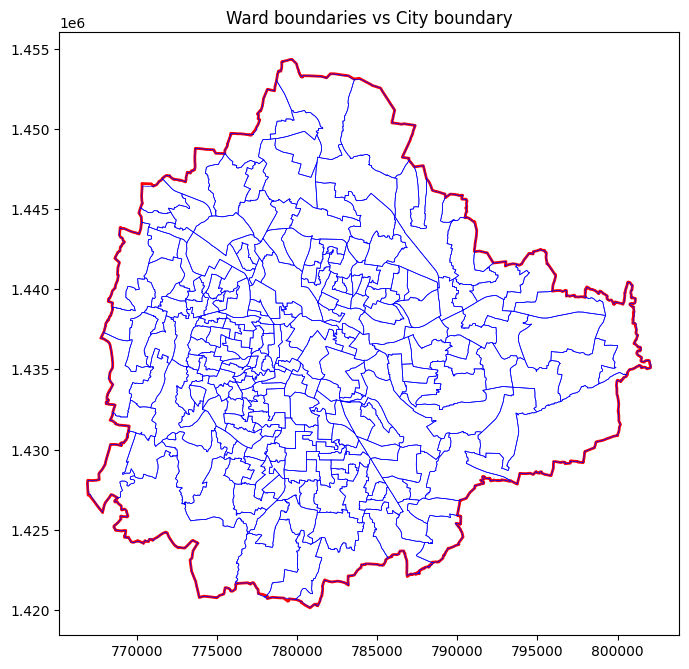

In [829]:
fig, ax = plt.subplots(figsize=(8, 8))
city_proj.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=2)
wards_proj.plot(ax=ax, facecolor='none', edgecolor='blue', linewidth=0.5)
plt.title("Ward boundaries vs City boundary")
plt.show()

In [831]:
geometry = gpd.points_from_xy(df['x'], df['y']) # Converts the co-ordinates into Points
df_gpd = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:32643") # converts the DataFrame into a GeoDataFrame

In [833]:
gdf = gpd.sjoin(df_gpd, wards_proj, predicate="within") # Joins the Points into the wards

In [834]:
geometry = gpd.points_from_xy(filtered_df['x'], filtered_df['y']) # Same process for the hotspots only
filtered_df_gpd = gpd.GeoDataFrame(filtered_df, geometry=geometry, crs="EPSG:32643") 

In [837]:
filtered_gdf = gpd.sjoin(filtered_df_gpd, wards_proj, predicate="within")

In [838]:
# Ward-wise metrics

ward_lst = gdf.groupby("name_en")["LST"].mean()
ward_pixels_count = gdf.groupby("name_en")["LST"].count()

ward_trees = filtered_gdf.groupby("name_en")["delta_trees"].mean()
ward_roof = filtered_gdf.groupby("name_en")["delta_roof"].mean()
ward_hotspot_pixels_count = filtered_gdf.groupby("name_en")["delta_roof"].count()

In [839]:
ward_stats = pd.DataFrame({
    "mean_lst": ward_lst,
    "total_pixels": ward_pixels_count,
    "mean_cooling_trees": ward_trees,
    "mean_cooling_roof": ward_roof,
    "hotspot_pixels": ward_hotspot_pixels_count
}).reset_index()

ward_stats["hotspot_area_km2"] = ward_stats["hotspot_pixels"] * 0.0009

ward_stats = ward_stats.sort_values("mean_lst", ascending=False).reset_index(drop=True)

joined = wards_proj.merge(ward_stats, on = "name_en", how = "left")

joined_proj = joined.to_crs(crs = "EPSG:4326")

## 8. Interactive Map

In [841]:
import folium

m = folium.Map( # Creates a map
    location=[12.97, 77.59],
    zoom_start=11
)

folium.GeoJson(joined_proj).add_to(m)

In [842]:
folium.Choropleth( # Adds colour to each ward based on the LST
    geo_data=joined_proj,
    data=ward_stats,
    columns=["name_en", "mean_lst"],
    key_on="feature.properties.name_en",
    fill_color="YlOrRd",
    fill_opacity=0.7,
    line_opacity=0.3,
    legend_name="Mean Land Surface Temperature (°C)",
    name="LST Choropleth"
).add_to(m)

In [843]:
folium.GeoJson( # Adds statistics to each ward
    joined_proj,
    style_function=lambda x: {
        "fillColor": "transparent",
        "color": "black",
        "weight": 0.5
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["name_en", "mean_lst", "mean_cooling_trees", "mean_cooling_roof", "hotspot_area_km2"],
        aliases=["Ward", "Mean LST (°C)", "Tree Cooling (°C)", "Green Roof Cooling (°C)", "Hotspot Area (km²)"],
        localize=True,
        sticky=True
    )
).add_to(m)

In [844]:
m

In [845]:
folium.LayerControl().add_to(m)
m.save(out_dir + r"\bengaluru_uhi_map.html")